# 01 – Exploratory analysis of laser weld thermal frames

**Question:** what does a thermal (LWIR) camera see when a laser beam weld turns from *sound* to *unsound*, and which simple signals could a model use?

Before running this notebook I ran, in the terminal:
```
python -m laser_defect.download
python -m laser_defect.data
```
All plotting functions live in `src/laser_defect/explore.py`, so they are tested and re-usable.

In [1]:
# I make the notebook work from the project folder, because my data paths
# (data/processed/frames.npz) are written relative to it.
import os
from pathlib import Path

if Path.cwd().name == "notebooks":      # VS Code starts notebooks inside notebooks/
    os.chdir("..")                      # so I move one folder up, to the project folder
print("Working folder:", Path.cwd())

Working folder: /Users/deep-mac/Documents/Github-repository/portfolio-DS-ML-AI/laser-defect-inspection-ml


In [2]:
# I import my own functions from phase 1 and phase 2.
import matplotlib.pyplot as plt
from laser_defect.explore import (
    prepare, plot_example_frames, plot_weld_timeline, plot_camera_scales,
    plot_feature_by_label, plot_position_by_label,
)

# I load the data and add the simple per-frame numbers (mean, max, std, range),
# the weld-relative versions (_z) and each frame's position inside its weld.
X, stats = prepare()
print(X.shape)          # (frames, 32, 32)
stats.head()

(16362, 32, 32)


,weld,speed_m_per_min,frame,y,high_scale,label,mean,max,std,range,mean_z,max_z,std_z,range_z,position
0,001-000,1,31,0,True,Sound,31634.890625,40197.0,2498.390137,10385.0,-0.718699,1.964827,2.043076,3.191085,0.000000
1,001-000,1,32,0,True,Sound,32931.785156,40314.0,2936.833252,10496.0,0.563911,2.019946,2.815775,3.257469,0.005348
2,001-000,1,33,0,True,Sound,34046.210938,40296.0,2599.126221,9337.0,1.666062,2.011467,2.220610,2.564326,0.010695
3,001-000,1,34,0,True,Sound,34338.402344,40164.0,2462.551025,8551.0,1.955035,1.949281,1.979914,2.094256,0.016043
4,001-000,1,35,0,True,Sound,33968.738281,40038.0,2138.612549,8351.0,1.589443,1.889921,1.409014,1.974646,0.021390


## 1. How much data do I have?
One row per frame. `y = 1` means Unsound (the defect I want to detect).

In [3]:
# I count frames per label and welding speed.
import pandas as pd
pd.crosstab(stats["label"], stats["speed_m_per_min"], margins=True)

speed_m_per_min,1,5,All
label,,,
Sound,8829,2048,10877
Unsound,4130,1355,5485
All,12959,3403,16362


## 2. What do the frames look like?
Each frame is 32 × 32 pixels. The bright horizontal band is the heat along the weld seam.

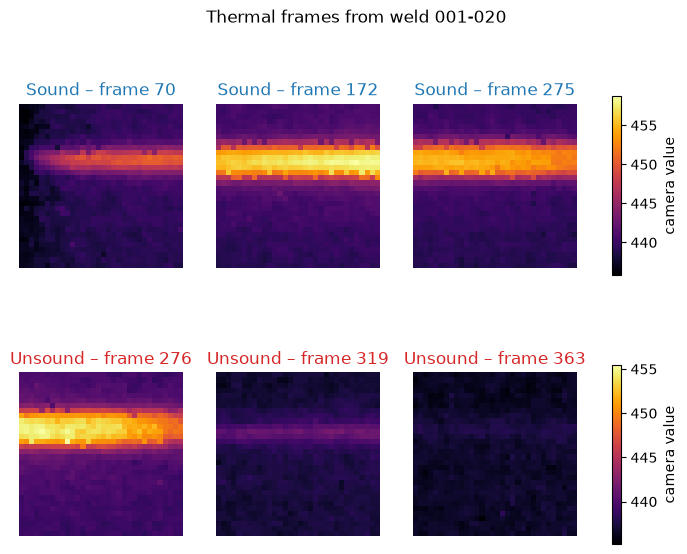

In [4]:
# I show 3 Sound and 3 Unsound frames from one weld, spaced evenly in time.
fig = plot_example_frames(X, stats, "001-020")
plt.show()

**What I see:** sound frames have a sharp, hot band. Unsound frames get cooler and more uniform. The *first* unsound frame (276) still looks like a sound frame, so the label boundary is not visible in every single frame: a model will make mistakes right at the transition.

## 3. How does a weld change over time?

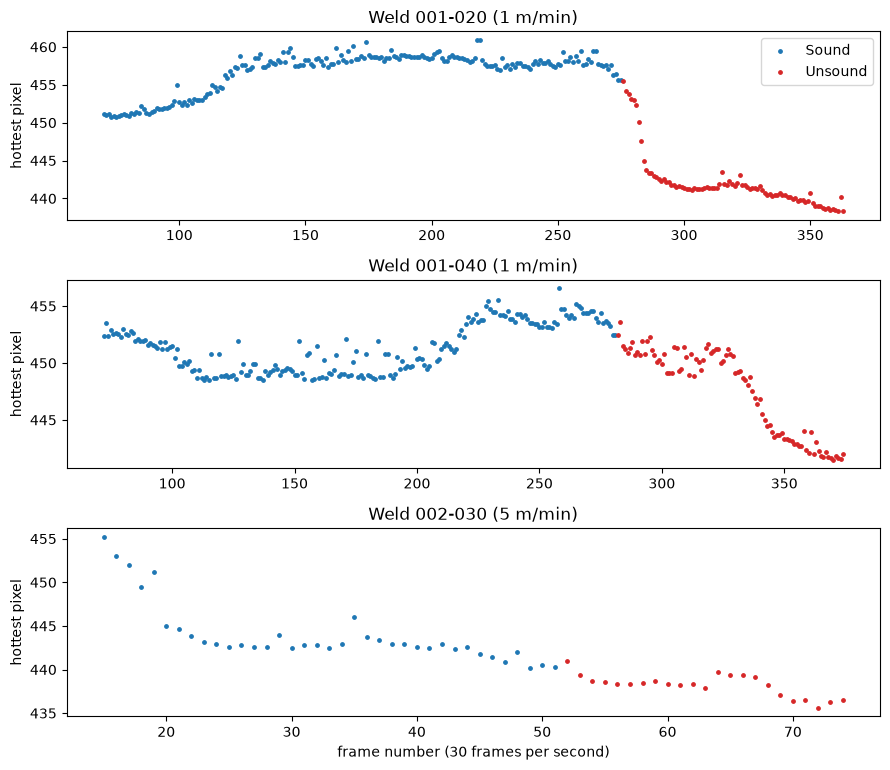

In [5]:
# I plot the hottest pixel of every frame over time for three welds.
fig = plot_weld_timeline(stats, ["001-020", "001-040", "002-030"])
plt.show()

**What I see:** the hottest pixel stays high while the weld is sound, then drops when it turns unsound. In weld 001-040 the drop starts *after* the label changes, so the signal can lag the label.

## 4. Two camera scales
Phase 1 found 29 welds stored on a different scale. I must not compare raw values across welds.

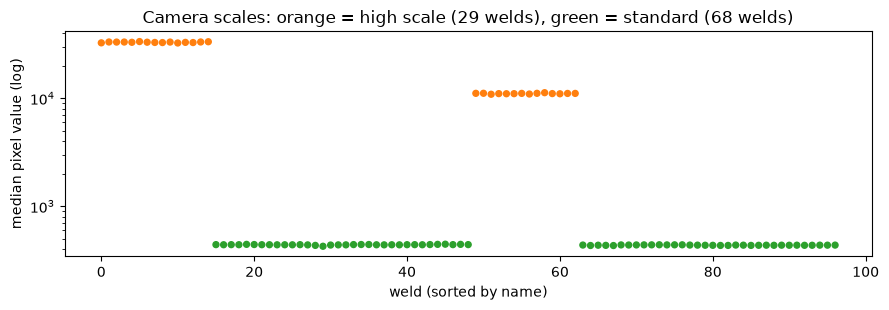

In [6]:
# I plot each weld's median pixel value on a log scale.
fig = plot_camera_scales(stats)
plt.show()

**What I see:** standard welds sit around 430; the high-scale welds sit around 33,000 (1 m/min group) and 11,000 (5 m/min group). So I compare frames *relative to their own weld* (z-scores) from now on.

## 5. Which simple numbers separate Sound from Unsound?

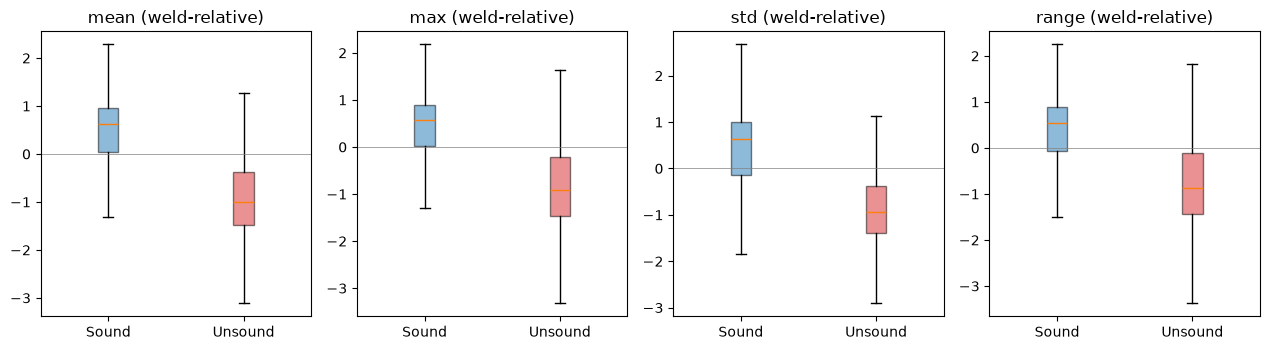

,mean_z,max_z,std_z,range_z
label,,,,
Sound,0.62,0.57,0.63,0.54
Unsound,-0.99,-0.91,-0.95,-0.88


In [7]:
# I compare weld-relative mean, max, spread (std) and range per label.
fig = plot_feature_by_label(stats)
plt.show()

# I also print the medians as numbers.
stats.groupby("label")[["mean_z", "max_z", "std_z", "range_z"]].median().round(2)

**What I see:** all four numbers are clearly lower for unsound frames (about −1 vs +0.6). The boxes overlap only a little, so even simple features should work. Phase 3 builds better, physics-motivated features.

## 6. Warning: is "Unsound" just "late in the weld"?

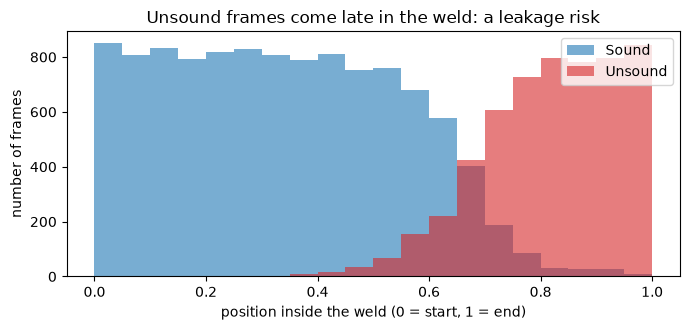

label
Sound      0.33
Unsound    0.83
Name: position, dtype: float64

In [8]:
# I plot where in the weld (0 = start, 1 = end) each label occurs.
fig = plot_position_by_label(stats)
plt.show()
stats.groupby("label")["position"].median().round(2)

**What I see:** unsound frames are almost always in the last third of the weld. A model could get a good score by learning *time* instead of *heat*. In phase 4 I will:
1. train a model on position only, as a "cheating" baseline, and
2. require my real model, which never sees time, to be judged against it, with the split made **per weld** so no weld is in both training and test data.

## Summary
- 16,362 frames, 97 welds, 1/3 unsound.
- Unsound frames are cooler and more uniform; the change can lag the label.
- Two camera scales → always normalise per weld.
- Strong time-order pattern → test for leakage and split by weld.